Changing the Flow from the chatflow

In [1]:
import os
import sys
import json
from pathlib import Path

from pydantic import BaseModel, Field
from typing import Annotated, TypedDict, List

from langchain_core.messages import AnyMessage, AIMessage, HumanMessage, SystemMessage
from langchain_core.output_parsers import StrOutputParser
from langchain_aws import ChatBedrockConverse
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver


PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from Tools.log_tools import log_fetch_tools

In [2]:
llm_config = {
    'model': "us.anthropic.claude-sonnet-4-6",
    'region_name': "us-east-1"
}
checkpointer = MemorySaver()

llm = ChatBedrockConverse(**llm_config)

In [3]:
class IssueReport(BaseModel):
    category: str = Field(description = 'Category of the issue. It can be one of the following: Bug, Performance Issue, Security Issue, Others, etc. The category should be determined based on the nature of the issue and its impact on the system.')
    priority: str = Field(description = 'Priority of the issue. It can be one of the following: P1, P2, P3, P4. Where P1 is the highest priority and P4 is the lowest priority. The priority should be determined based on the severity of the issue and its impact on the system.')
    issue: str = Field(description = 'A brief description of the issue. It should provide enough information to understand the nature of the problem and its impact on the system.')
    generic_recommendation: str | None = Field(description = 'A generic recommendation for addressing the issue. It should provide a high-level suggestion for resolving the problem, without going into specific implementation details.')
    specific_recommendation: str | None = Field(description = 'A specific recommendation for addressing the issue. It should only be provided if there is mention of the solution in the docs provided else None.', default = None)
    solution_steps: List[str] | None = Field(description = 'A list of specific steps in order to implement the solution. It should only be provided if there is mention of the solution in the docs provided else None.', default = None)

class IssuesReported(BaseModel):
    issues: List[IssueReport] = Field(description = 'A list of issues reported. Each issue should be represented as an instance of the IssueReport model, providing detailed information about the issue, its category, priority, and recommendations for resolution.')

In [4]:
sonnet_config = {
    'model': "us.anthropic.claude-sonnet-4-6",
    'region_name': "us-east-1"
}
haiku_config = {
    # Use inference profile ID from list_inference_profiles(), NOT list_foundation_models()
    'model': "us.anthropic.claude-haiku-4-5-20251001-v1:0",
    'region_name': "us-east-1"
}
checkpointer = MemorySaver()

haiku_llm = ChatBedrockConverse(**haiku_config).with_structured_output(IssuesReported)
sonnet_llm = ChatBedrockConverse(**sonnet_config).bind_tools(log_fetch_tools)

In [5]:
from operator import add

class FlowState(TypedDict):
    messages: Annotated[List[AnyMessage], add_messages]
    logs: Annotated[List[dict], add]
    issues: IssuesReported | None

In [7]:
from langchain_core.messages import ToolMessage

_log_tool_node = ToolNode(log_fetch_tools)


def _parse_tool_logs(content) -> list[dict]:
    if isinstance(content, list):
        return [entry for entry in content if isinstance(entry, dict)]
    if isinstance(content, str):
        try:
            parsed = json.loads(content)
        except json.JSONDecodeError:
            return []
        if isinstance(parsed, list):
            return [entry for entry in parsed if isinstance(entry, dict)]
    return []


def _format_issue_item(issue_item: IssueReport) -> str:
    lines = [
        f"Category: {issue_item.category}",
        f"Priority: {issue_item.priority}",
        f"Issue: {issue_item.issue}",
    ]
    if issue_item.generic_recommendation:
        lines.append(f"Generic recommendation: {issue_item.generic_recommendation}")
    if issue_item.specific_recommendation:
        lines.append(f"Specific recommendation: {issue_item.specific_recommendation}")
    if issue_item.solution_steps:
        lines.append("Solution steps:")
        lines.extend(f"  - {step}" for step in issue_item.solution_steps)
    return "\n".join(lines)


def issues_to_message(reported: IssuesReported) -> AIMessage:
    if not reported.issues:
        return AIMessage(content="No issues were identified in the analyzed logs.")

    issue_blocks = [
        f"Issue {index}:\n{_format_issue_item(item)}"
        for index, item in enumerate(reported.issues, start=1)
    ]
    return AIMessage(
        content="\n\n".join(issue_blocks),
        additional_kwargs={"issues_report": reported.model_dump()},
    )


def orch_node(state: FlowState) -> FlowState:
    messages = state.get('messages', '')
    response = sonnet_llm.invoke(messages)
    return {'messages': [response]}


def tools_node(state: FlowState) -> FlowState:
    result = _log_tool_node.invoke(state)
    fetched_logs: list[dict] = []
    for message in result.get('messages', []):
        if isinstance(message, ToolMessage):
            fetched_logs.extend(_parse_tool_logs(message.content))
    return {
        'messages': result.get('messages', []),
        'logs': fetched_logs,
    }


def parser_node(state: FlowState) -> FlowState:
    messages = state.get('messages', '')
    reported = haiku_llm.invoke(messages)
    return {
        'messages': [issues_to_message(reported)],
        'issues': reported,
    }

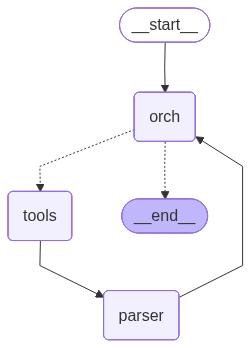

In [8]:
builder = StateGraph(FlowState)
builder.add_node('orch', orch_node)
builder.add_node('tools', tools_node)
builder.add_node('parser', parser_node)

builder.add_edge(START, 'orch')
builder.add_conditional_edges('orch', tools_condition)
builder.add_edge('tools', 'parser')
builder.add_edge('parser', 'orch')
# builder.add_edge('parser', END)

graph = builder.compile(checkpointer = checkpointer)
graph

In [9]:
log_file_path = r'C:\Data\Project\ASBG\LogAnalyser\logs\LOGS_POOL_DUMP\PoolServer1\ServerManager.log'
thread_id = 'test_2'

response = graph.invoke({
    'messages': [
        SystemMessage(content = f"The log file path is {log_file_path}"),
        HumanMessage(content = "Can you give me the latest logs of the system?")
    ]
}, config = {'configurable': {'thread_id': thread_id}})
response['issues']

ValidationException: An error occurred (ValidationException) when calling the Converse operation: The model returned the following errors: This model does not support assistant message prefill. The conversation must end with a user message.